# DATA 250 PROJECT 4 - Phase 2
Student: Minh Pham

# Introduction

In this phase of the project, I compare three classification methods (K-Nearest Neighbors, logistic regression, and random forests) to predict whether the home team wins a soccer match. The goal is to tune each model carefully and evaluate them on the same train/test split.

To keep the comparison fair, I split the data once at the start and reserve the test set for the very end. All model selection, tuning, and feature engineering decisions are made using only the training data.

First, I import the required packages and prepare the modeling dataset.

In [75]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    validation_curve,
    GridSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, confusion_matrix

import statsmodels.api as sm

# Load and Prepare the Data

The response variable is `HomeWin`, coded as 1 when `home_team_goal > away_team_goal` and 0 otherwise.

Based on my Phase 1 analysis, I use six quantitative predictors (`avg_home_odds`, `avg_draw_odds`, `avg_away_odds`, `stage`, `month`, `day_of_week`) and two categorical predictors (`league_id`, `season`).

In [76]:
# Connect to the SQLite database
conn = sqlite3.connect(
    r"E:\data250_2026sp\Project 4\hugomathien\soccer\versions\10\database.sqlite"
)

# Load Match table
df = pd.read_sql("SELECT * FROM Match;", conn)
conn.close()

# Response variable
df["HomeWin"] = (df["home_team_goal"] > df["away_team_goal"]).astype(int)

# Averaged betting-odds features
df["avg_home_odds"] = df[["B365H", "BWH", "IWH"]].mean(axis=1)
df["avg_draw_odds"] = df[["B365D", "BWD", "IWD"]].mean(axis=1)
df["avg_away_odds"] = df[["B365A", "BWA", "IWA"]].mean(axis=1)

# Date-based features
df["month"] = pd.to_datetime(df["date"]).dt.month
df["day_of_week"] = pd.to_datetime(df["date"]).dt.dayofweek

quant_features = [
    "avg_home_odds",
    "avg_draw_odds",
    "avg_away_odds",
    "stage",
    "month",
    "day_of_week"
]
cat_features = ["league_id", "season"]
all_features = quant_features + cat_features

model_df = df[all_features + ["HomeWin"]].dropna().copy()
X = model_df[all_features].copy()
y = model_df["HomeWin"].copy()

print("Dataset shape after dropping missing values:", model_df.shape)
print("\nMissing values by column:")
print(model_df.isnull().sum())

Dataset shape after dropping missing values: (22596, 9)

Missing values by column:
avg_home_odds    0
avg_draw_odds    0
avg_away_odds    0
stage            0
month            0
day_of_week      0
league_id        0
season           0
HomeWin          0
dtype: int64


# Train/Test Split

I split the data into training and test sets using an 80/20 split with stratification. From this point forward, the test set is untouched until final model evaluation.

In [77]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

Training set shape: (18076, 8)
Test set shape: (4520, 8)


# KNN Classifier

KNN is fit using only quantitative predictors, and those predictors are standardized because KNN is distance-based.

I tune `k` by cross-validation over odd values from 1 to 99.

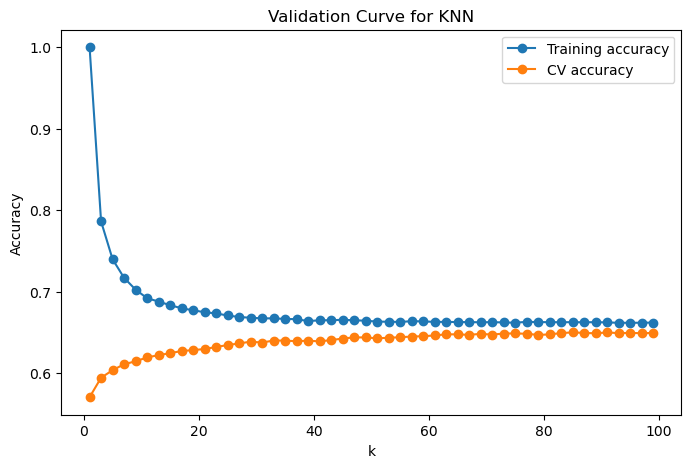

Selected k: 85


KNeighborsClassifier(n_neighbors=85)

In [78]:
knn_scaler = StandardScaler()
X_train_quant = X_train[quant_features]
X_test_quant = X_test[quant_features]

X_train_quant_scaled = knn_scaler.fit_transform(X_train_quant)
X_test_quant_scaled = knn_scaler.transform(X_test_quant)

k_range = np.arange(1, 101, 2)
train_scores, val_scores = validation_curve(
    estimator=KNeighborsClassifier(),
    X=X_train_quant_scaled,
    y=y_train,
    param_name="n_neighbors",
    param_range=k_range,
    cv=5,
    scoring="accuracy"
)

mean_train_scores = train_scores.mean(axis=1)
mean_val_scores = val_scores.mean(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(k_range, mean_train_scores, marker="o", label="Training accuracy")
plt.plot(k_range, mean_val_scores, marker="o", label="CV accuracy")
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.title("Validation Curve for KNN")
plt.legend()
plt.show()

best_k = int(k_range[np.argmax(mean_val_scores)])
print("Selected k:", best_k)

final_knn = KNeighborsClassifier(n_neighbors=best_k)
final_knn.fit(X_train_quant_scaled, y_train)

The validation curve rises quickly for small values of `k` and then levels off, while training accuracy decreases as expected with smoother decision boundaries. This is the bias-variance tradeoff in practice: very small `k` overfits, while larger `k` is more stable.

In my run, the best value was **k = 85**, so I used a relatively large neighborhood for the final KNN model.

# Logistic Regression

For logistic regression, I keep predictors unscaled so coefficient interpretation is straightforward.

I start with forward selection on the six quantitative predictors.

Forward selection order:
1. avg_home_odds
2. avg_draw_odds
3. avg_away_odds
4. day_of_week
5. stage
6. month


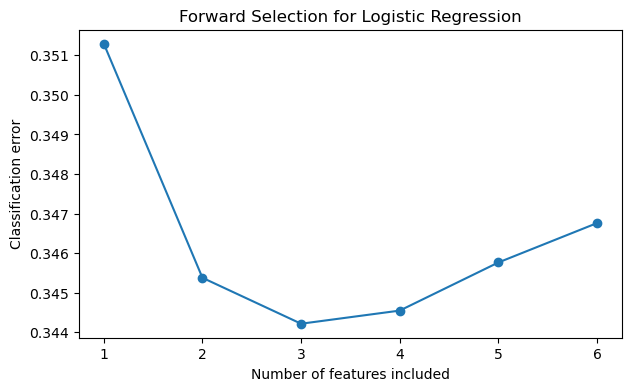

Initial quantitative subset: ['avg_home_odds', 'avg_draw_odds', 'avg_away_odds']


In [89]:
LOGIT_KWARGS = {"max_iter": 4000, "penalty": None}

def cv_classification_error(X_data, y_data, feature_list, cv=5):
    model = LogisticRegression(**LOGIT_KWARGS)
    scores = cross_val_score(
        model,
        X_data[feature_list],
        y_data,
        cv=cv,
        scoring="accuracy"
    )
    return 1 - scores.mean()

remaining_features = quant_features.copy()
selected_features = []
forward_errors = []
selection_order = []

for _ in range(len(quant_features)):
    best_feature = None
    best_error = np.inf

    for feature in remaining_features:
        trial_features = selected_features + [feature]
        error = cv_classification_error(X_train, y_train, trial_features)

        if error < best_error:
            best_error = error
            best_feature = feature

    selected_features.append(best_feature)
    remaining_features.remove(best_feature)
    selection_order.append(best_feature)
    forward_errors.append(best_error)

print("Forward selection order:")
for i, feature in enumerate(selection_order, start=1):
    print(f"{i}. {feature}")

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(forward_errors) + 1), forward_errors, marker="o")
plt.xlabel("Number of features included")
plt.ylabel("Classification error")
plt.title("Forward Selection for Logistic Regression")
plt.xticks(range(1, len(forward_errors) + 1))
plt.show()

best_num_quant = int(np.argmin(forward_errors) + 1)
initial_quant_features = selection_order[:best_num_quant]
print("Initial quantitative subset:", initial_quant_features)

The forward-selection order was:
1. `avg_home_odds`
2. `avg_draw_odds`
3. `avg_away_odds`
4. `day_of_week`
5. `stage`
6. `month`

The cross-validated classification error reached its minimum at 3 features, so I selected this initial quantitative subset:
- `avg_home_odds`
- `avg_draw_odds`
- `avg_away_odds`

After three predictors, adding more variables did not reduce error further, so the 3-feature model is the best balance of performance and simplicity.

I then tested whether adding categorical predictors (`league_id`, `season`) improved performance.

In [ ]:
# Quantitative-only baseline
quant_log_model = LogisticRegression(**LOGIT_KWARGS)
quant_log_scores = cross_val_score(
    quant_log_model,
    X_train[initial_quant_features],
    y_train,
    cv=5,
    scoring="accuracy"
)

# Add categorical predictors using dummies
X_train_cat = pd.get_dummies(X_train[cat_features], 
                             drop_first=True, dtype=float)
X_test_cat = pd.get_dummies(X_test[cat_features], 
                            drop_first=True, dtype=float)
X_train_cat, X_test_cat = X_train_cat.align(X_test_cat, 
                                            join="left", axis=1, 
                                            fill_value=0)

X_train_log_cat = pd.concat([X_train[initial_quant_features], X_train_cat], axis=1)

cat_log_model = LogisticRegression(**LOGIT_KWARGS)
cat_log_scores = cross_val_score(
    cat_log_model,
    X_train_log_cat,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("CV accuracy (quantitative-only):", quant_log_scores.mean())
print("CV accuracy (quantitative + categorical):", cat_log_scores.mean())

CV accuracy (quantitative-only): 0.655786163233332
CV accuracy (quantitative + categorical): 0.6541817678306956


After selecting the three strongest quantitative predictors, `avg_home_odds`, `avg_away_odds`, and `avg_draw_odds`, I evaluated whether adding the categorical variables `league_id` and `season` improved model performance. After converting these variables into dummy columns, the resulting model achieved a cross-validated accuracy of 0.6545.

This was slightly worse than the quantitative-only logistic regression model, so the categorical predictors did not appear to add meaningful predictive information beyond what was already captured by the betting-odds variables. Because they increased model complexity without improving performance, I did not retain them in the final logistic regression model.

## Logistic Feature Engineering

I next tested nontrivial feature engineering on the selected quantitative predictors:
- squared terms for each odds variable
- `odds_gap = avg_away_odds - avg_home_odds`

I compare this engineered model to the original 3-feature logistic model using 5-fold CV on the training data only.

In [81]:
# Base logistic design matrix
X_train_log_base = X_train[initial_quant_features].copy()
X_test_log_base = X_test[initial_quant_features].copy()

# Engineered design matrix
X_train_log_fe = X_train_log_base.copy()
X_test_log_fe = X_test_log_base.copy()

for col in ["avg_home_odds", "avg_away_odds", "avg_draw_odds"]:
    X_train_log_fe[f"{col}_sq"] = X_train_log_fe[col] ** 2
    X_test_log_fe[f"{col}_sq"] = X_test_log_fe[col] ** 2

X_train_log_fe["odds_gap"] = X_train["avg_away_odds"] - X_train["avg_home_odds"]
X_test_log_fe["odds_gap"] = X_test["avg_away_odds"] - X_test["avg_home_odds"]

base_scores = cross_val_score(
    LogisticRegression(**LOGIT_KWARGS),
    X_train_log_base,
    y_train,
    cv=5,
    scoring="accuracy"
)

fe_scores = cross_val_score(
    LogisticRegression(**LOGIT_KWARGS),
    X_train_log_fe,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("CV accuracy (base logistic):", base_scores.mean())
print("CV accuracy (feature-engineered logistic):", fe_scores.mean())

if fe_scores.mean() > base_scores.mean():
    final_log_features = list(X_train_log_fe.columns)
    X_train_log_final = X_train_log_fe.copy()
    X_test_log_final = X_test_log_fe.copy()
    print("Selected final logistic feature set: engineered")
else:
    final_log_features = list(X_train_log_base.columns)
    X_train_log_final = X_train_log_base.copy()
    X_test_log_final = X_test_log_base.copy()
    print("Selected final logistic feature set: base")

print("Final logistic features:", final_log_features)

CV accuracy (base logistic): 0.655786163233332
CV accuracy (feature-engineered logistic): 0.6550116892495624
Selected final logistic feature set: base
Final logistic features: ['avg_home_odds', 'avg_draw_odds', 'avg_away_odds']


To make the logistic regression model more flexible, I tried several engineered features based on the betting-odds variables, since these were the strongest predictors in Phase 1. In particular, I tested squared terms for the home and away odds as well as an `odds_gap` variable measuring the difference between away and home odds.

The base logistic regression model achieved a cross-validated accuracy of 0.6558, while the feature-engineered version achieved a slightly lower accuracy of 0.6550. Since the engineered features did not improve performance, I kept the simpler base model. This suggests that the relationship between the selected odds variables and the response was already captured well enough by the original linear terms.

## Final Logistic Model (`sklearn` and `statsmodels`)

In [ ]:
# Final sklearn logistic model
final_log_model = LogisticRegression(**LOGIT_KWARGS)
final_log_model.fit(X_train_log_final, y_train)

print("Final sklearn logistic coefficients:")
coef_table = pd.DataFrame({
    "feature": X_train_log_final.columns,
    "coefficient": final_log_model.coef_.ravel()
}).sort_values("coefficient", key=np.abs, ascending=False)
print(coef_table)

# Final statsmodels logistic model for inference
X_train_sm = sm.add_constant(X_train_log_final)
final_log_sm = sm.Logit(y_train, X_train_sm).fit(disp=0)
print(final_log_sm.summary())

# Check sklearn vs statsmodels agreement
sk_params = pd.Series(
    np.r_[final_log_model.intercept_[0], 
          final_log_model.coef_.ravel()],
    index=["const"] + list(X_train_log_final.columns)
)
sm_params = final_log_sm.params.reindex(sk_params.index)
comparison = pd.DataFrame({
    "sklearn": sk_params,
    "statsmodels": sm_params,
    "abs_diff": (sk_params - sm_params).abs()
})
print("\nCoefficient comparison (sklearn vs statsmodels):")
print(comparison)
print("Max absolute difference:", comparison["abs_diff"].max())

# Odds ratios and significance summary for interpretation
logit_summary = pd.DataFrame({
    "coef": final_log_sm.params,
    "p_value": final_log_sm.pvalues,
    "odds_ratio": np.exp(final_log_sm.params)
}).drop(index="const", errors="ignore")

notable_features = logit_summary.sort_values("p_value").head(3)
print("\nMost statistically notable predictors (by p-value):")
print(notable_features)

Final sklearn logistic coefficients:
         feature  coefficient
0  avg_home_odds    -0.406940
1  avg_draw_odds     0.240495
2  avg_away_odds     0.104275
                           Logit Regression Results                           
Dep. Variable:                HomeWin   No. Observations:                18076
Model:                          Logit   Df Residuals:                    18072
Method:                           MLE   Df Model:                            3
Date:                Wed, 22 Apr 2026   Pseudo R-squ.:                  0.1089
Time:                        18:48:21   Log-Likelihood:                -11111.
converged:                       True   LL-Null:                       -12469.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -0.5030      0.130     -3.880 

The final logistic regression model was selected by combining the results of forward selection, the categorical-feature comparison, and the feature-engineering step. Forward selection showed that the best quantitative subset was `avg_home_odds`, `avg_draw_odds`, and `avg_away_odds`. Adding the categorical predictors slightly reduced cross-validated accuracy, and the engineered features also failed to improve performance, so I retained the simpler base model.

I then fit this final model in both scikit-learn and statsmodels and confirmed that the estimated coefficients were essentially identical, with a maximum absolute difference of about 0.00027. Among the predictors, `avg_home_odds` was the most statistically notable variable and had a negative coefficient, meaning that lower home-team odds were associated with a higher probability of a home win. Both `avg_draw_odds` and `avg_away_odds` were also statistically significant and had positive coefficients, indicating that as those odds increased, the predicted probability of a home win also increased.

# Random Forest

For random forests, I use unscaled quantitative predictors and tune `n_estimators` and `max_depth` with `GridSearchCV` on the training set.

Best RF parameters: {'max_depth': 8, 'n_estimators': 400}
Best RF CV accuracy: 0.6521350322525368


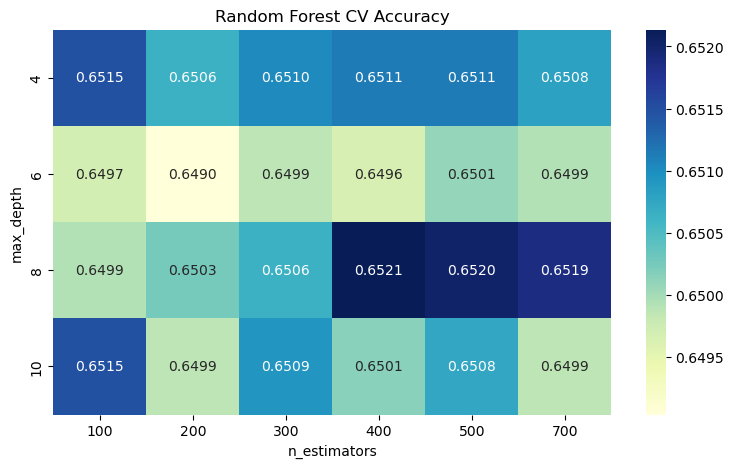

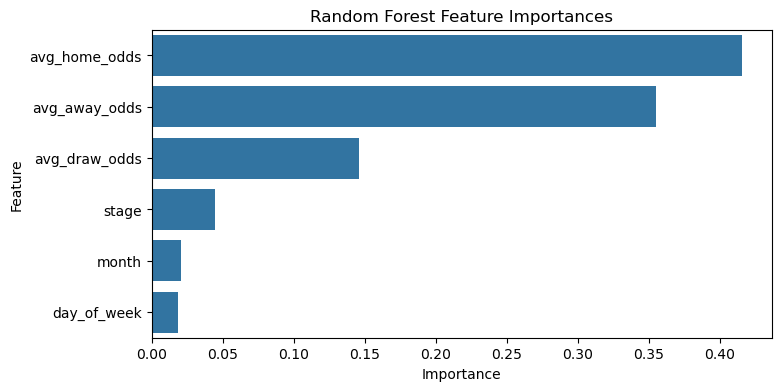

Feature importances:
avg_home_odds    0.415608
avg_away_odds    0.354873
avg_draw_odds    0.145816
stage            0.044539
month            0.020493
day_of_week      0.018670
dtype: float64


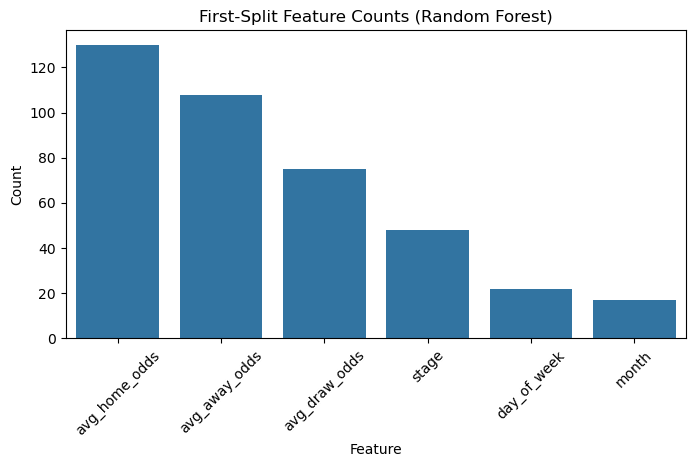

First-split counts:
avg_home_odds    130
avg_away_odds    108
avg_draw_odds     75
stage             48
day_of_week       22
month             17
dtype: int64


In [83]:
rf_param_grid = {
    "n_estimators": [100, 200, 300, 400, 500, 700],
    "max_depth": [4, 6, 8, 10]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=rf_param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=1
)
rf_grid.fit(X_train[quant_features], y_train)

print("Best RF parameters:", rf_grid.best_params_)
print("Best RF CV accuracy:", rf_grid.best_score_)

# Heatmap of mean CV scores
rf_cv_results = pd.DataFrame(rf_grid.cv_results_)
heatmap_df = rf_cv_results.pivot_table(
    index="param_max_depth",
    columns="param_n_estimators",
    values="mean_test_score"
)

plt.figure(figsize=(9, 5))
sns.heatmap(heatmap_df, annot=True, fmt=".4f", cmap="YlGnBu")
plt.title("Random Forest CV Accuracy")
plt.xlabel("n_estimators")
plt.ylabel("max_depth")
plt.show()

# Final RF model
final_rf = rf_grid.best_estimator_

# Feature importances
rf_importance = pd.Series(
    final_rf.feature_importances_,
    index=quant_features
).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x=rf_importance.values, y=rf_importance.index, orient="h")
plt.title("Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

print("Feature importances:")
print(rf_importance)

# First-split counts across trees
first_split_counts = pd.Series(0, index=quant_features, dtype=int)
for tree in final_rf.estimators_:
    root_idx = tree.tree_.feature[0]
    if root_idx >= 0:
        first_split_counts.iloc[root_idx] += 1

first_split_counts = first_split_counts.sort_values(ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x=first_split_counts.index, y=first_split_counts.values)
plt.title("First-Split Feature Counts (Random Forest)")
plt.ylabel("Count")
plt.xlabel("Feature")
plt.xticks(rotation=45)
plt.show()

print("First-split counts:")
print(first_split_counts)

Grid search selected **`n_estimators = 400`** and **`max_depth = 8`** as the best random-forest settings, with CV accuracy **0.6521350322525368**.

Both importance approaches identify the same leading features. By `feature_importances_`, the top predictors are `avg_home_odds` (**0.4156**), `avg_away_odds` (**0.3549**), and `avg_draw_odds` (**0.1458**). First-split counts show the same ranking (`avg_home_odds`: **130**, `avg_away_odds`: **108**, `avg_draw_odds`: **75**), while `stage`, `day_of_week`, and `month` were used much less often.

# Final Evaluation on the Test Set

I now evaluate the final tuned versions of KNN, logistic regression, and random forest on the test set. This is the first time the test set is used for model comparison.

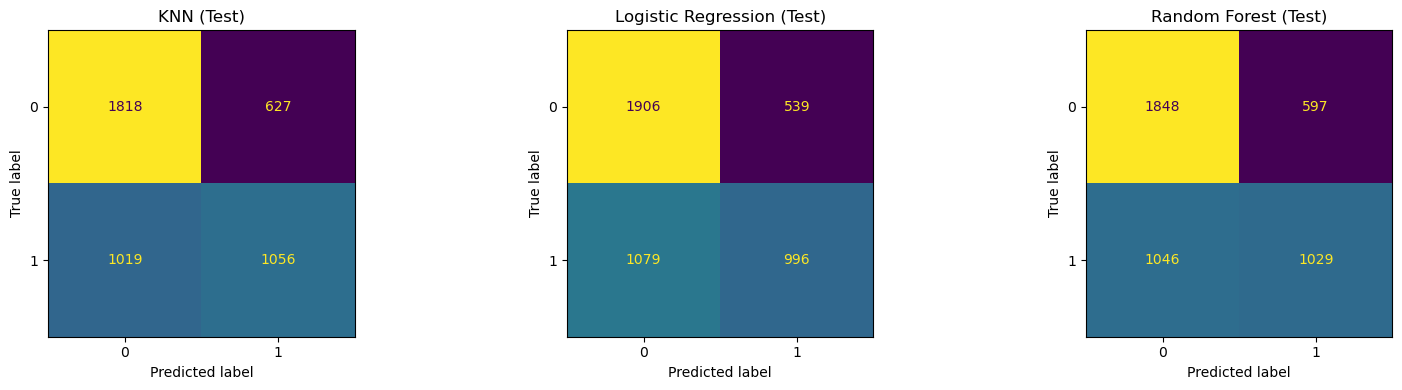

              Model                                       Final Parameters  Train Accuracy  Train Error  Test Accuracy  Test Error
Logistic Regression features = avg_home_odds, avg_draw_odds, avg_away_odds        0.655178     0.344822       0.642035    0.357965
      Random Forest                      n_estimators = 400, max_depth = 8        0.683005     0.316995       0.636504    0.363496
 K Nearest Neighbor                                                 k = 85        0.663200     0.336800       0.635841    0.364159


In [ ]:
# Predictions
y_train_pred_knn = final_knn.predict(X_train_quant_scaled)
y_test_pred_knn = final_knn.predict(X_test_quant_scaled)

y_train_pred_log = final_log_model.predict(X_train_log_final)
y_test_pred_log = final_log_model.predict(X_test_log_final)

y_train_pred_rf = final_rf.predict(X_train[quant_features])
y_test_pred_rf = final_rf.predict(X_test[quant_features])

# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred_knn, ax=axes[0], colorbar=False)
axes[0].set_title("KNN (Test)")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred_log, ax=axes[1], colorbar=False)
axes[1].set_title("Logistic Regression (Test)")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred_rf, ax=axes[2], colorbar=False)
axes[2].set_title("Random Forest (Test)")

plt.tight_layout()
plt.show()

# Results table
results_df = pd.DataFrame({
    "Model": ["K Nearest Neighbor", "Logistic Regression", "Random Forest"],
    "Final Parameters": [
        f"k = {best_k}",
        f"features = {', '.join(final_log_features)}",
        f"n_estimators = {rf_grid.best_params_['n_estimators']}, max_depth = {rf_grid.best_params_['max_depth']}"
    ],
    "Train Accuracy": [
        accuracy_score(y_train, y_train_pred_knn),
        accuracy_score(y_train, y_train_pred_log),
        accuracy_score(y_train, y_train_pred_rf)
    ],
    "Train Error": [
        1 - accuracy_score(y_train, y_train_pred_knn),
        1 - accuracy_score(y_train, y_train_pred_log),
        1 - accuracy_score(y_train, y_train_pred_rf)
    ],
    "Test Accuracy": [
        accuracy_score(y_test, y_test_pred_knn),
        accuracy_score(y_test, y_test_pred_log),
        accuracy_score(y_test, y_test_pred_rf)
    ],
    "Test Error": [
        1 - accuracy_score(y_test, y_test_pred_knn),
        1 - accuracy_score(y_test, y_test_pred_log),
        1 - accuracy_score(y_test, y_test_pred_rf)
    ]
}).sort_values("Test Accuracy", ascending=False)

print(results_df.to_string(index=False))

# Recommendation

Based on the final test-set results, I recommend the logistic regression model as the best overall classifier for this problem. It achieved the highest test accuracy at 0.6420, compared with 0.6365 for the random forest and 0.6358 for KNN. Although the differences are not extremely large, logistic regression performed slightly better than the other two methods while also remaining the most interpretable.

The random forest achieved the highest training accuracy, which suggests it fit the training data more closely, but that did not translate into better test performance. KNN also performed reasonably well, but it required a very large value of $k$, which suggests that this dataset benefits more from broad averaging than from local neighborhood structure. Overall, logistic regression provided the best balance between predictive performance, stability, and interpretability. This result is also consistent with my Phase 1 expectation that betting odds would be the most useful predictors and that a relatively simple model might perform well.

# Most Predictive Features

Both the logistic regression model and the random forest model identified the betting-odds variables as the most important predictors of home wins. In the logistic regression model, all three retained predictors were statistically significant: `avg_home_odds`, `avg_draw_odds`, and `avg_away_odds`. Among these, `avg_home_odds` was the strongest and most statistically significant predictor, with a coefficient of about -0.407 and an odds ratio of about 0.666. This indicates that lower home-team odds, which reflect stronger expectations that the home team will win, are associated with a higher probability of a home win. The other two predictors were also significant, with positive coefficients, suggesting that higher draw odds and higher away-team odds are associated with a greater chance of a home win.

The random forest model tells a very similar story. Its feature importances ranked `avg_home_odds` first (0.4156), `avg_away_odds` second (0.3549), and `avg_draw_odds` third (0.1458), while the remaining predictors, `stage`, `month`, and `day_of_week`, had much smaller importance values. This indicates that the betting-odds variables dominate the prediction task regardless of whether the model is linear or nonlinear. These findings are consistent with my Phase 1 EDA, where the betting odds appeared to be the strongest predictors of the response. Overall, both models support the conclusion that pre-match betting information is far more useful for predicting home wins than calendar-based variables.